## Решающее дерево из sklearn без стандартизации

In [1]:
import pandas as pd

from sklearn.datasets import fetch_california_housing
from sklearn.metrics import mean_squared_error
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [2]:
housing = fetch_california_housing()

In [3]:
X = pd.DataFrame(data=housing["data"], columns=housing["feature_names"])
y = housing["target"]

In [4]:
y

array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,))

In [22]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [23]:
X.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25


In [24]:
X.shape

(20640, 8)

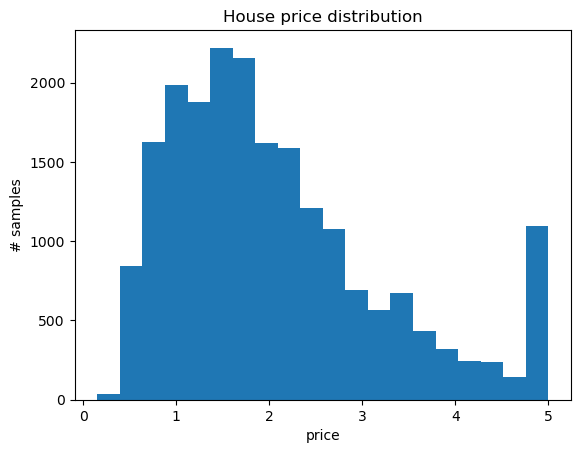

In [25]:
plt.title("House price distribution")
plt.xlabel("price")
plt.ylabel("# samples")
plt.hist(y, bins=20)
plt.show()

In [26]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)

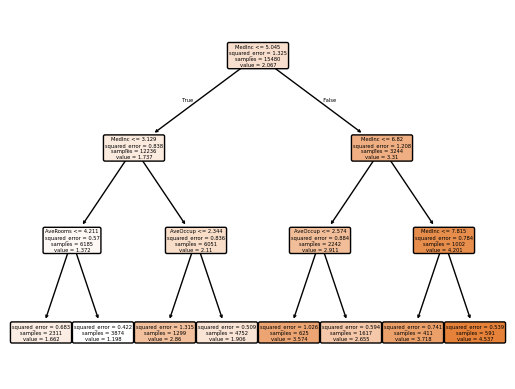

In [27]:
dt = DecisionTreeRegressor(max_depth=3, random_state=13)
dt.fit(X_train, y_train)

plot_tree(dt, feature_names=X.columns, filled=True, rounded=True)
plt.show()

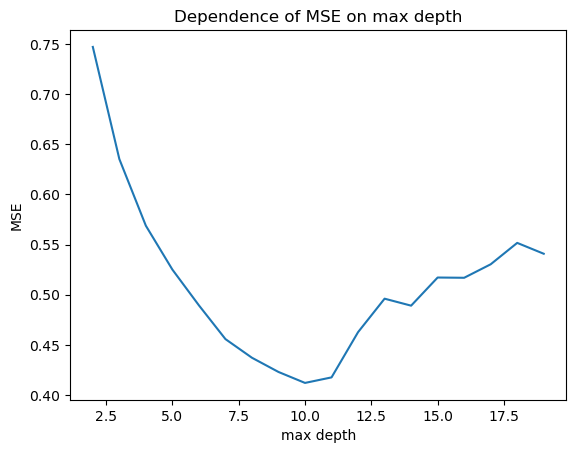

In [28]:
max_depth_array = range(2, 20)
mse_array = []

for max_depth in max_depth_array:
    dt = DecisionTreeRegressor(max_depth=max_depth, random_state=13)
    dt.fit(X_train, y_train)
    mse_array.append(mean_squared_error(y_test, dt.predict(X_test)))

plt.plot(max_depth_array, mse_array)
plt.title("Dependence of MSE on max depth")
plt.xlabel("max depth")
plt.ylabel("MSE")
plt.show()

In [29]:
pd.DataFrame({
    "max_depth": max_depth_array,
    "MSE": mse_array
}).sort_values(by="MSE").reset_index(drop=True)

,max_depth,MSE
0,10,0.412125
1,11,0.417647
2,9,0.423044
3,8,0.437202
4,7,0.455806
5,12,0.462736
6,14,0.489129
7,6,0.489436
8,13,0.496086
9,16,0.516918


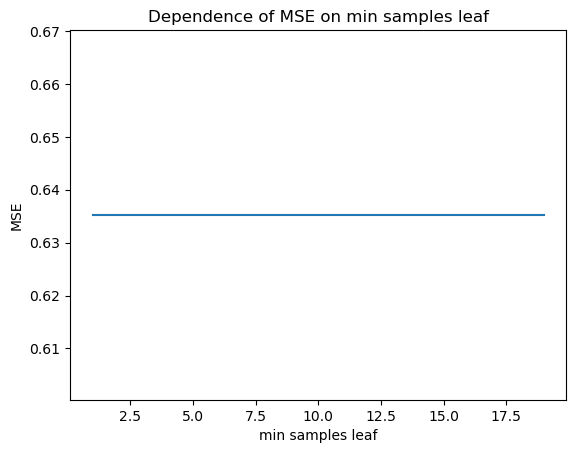

In [32]:
min_samples_leaf_array = range(1, 20)
mse_array = []

for min_samples_leaf in min_samples_leaf_array:
    dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=min_samples_leaf, random_state=13)
    dt.fit(X_train, y_train)
    mse_array.append(mean_squared_error(y_test, dt.predict(X_test)))

plt.plot(min_samples_leaf_array, mse_array)
plt.title("Dependence of MSE on min samples leaf")
plt.xlabel("min samples leaf")
plt.ylabel("MSE")
plt.show()

In [33]:
pd.DataFrame({
    "min_samples_leaf": min_samples_leaf_array,
    "MSE": mse_array
}).sort_values(by="MSE").reset_index(drop=True)

,min_samples_leaf,MSE
0,1,0.635242
1,2,0.635242
2,3,0.635242
3,4,0.635242
4,5,0.635242
5,6,0.635242
6,7,0.635242
7,8,0.635242
8,9,0.635242
9,10,0.635242


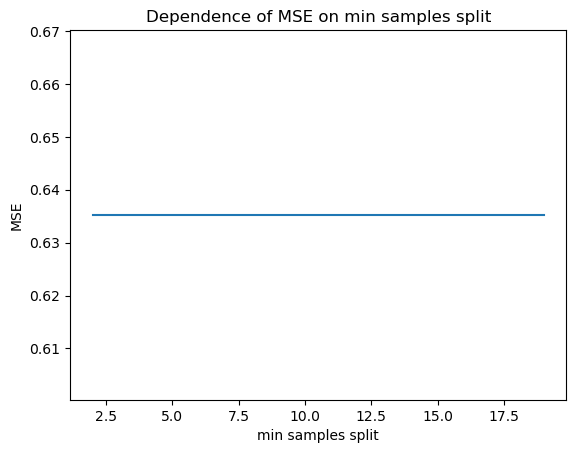

In [34]:
min_samples_split_array = range(2, 20)
mse_array = []

for min_samples_split in min_samples_split_array:
    dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=11, min_samples_split=min_samples_split, random_state=13)
    dt.fit(X_train, y_train)
    mse_array.append(mean_squared_error(y_test, dt.predict(X_test)))

plt.plot(min_samples_split_array, mse_array)
plt.title("Dependence of MSE on min samples split")
plt.xlabel("min samples split")
plt.ylabel("MSE")
plt.show()

In [35]:
pd.DataFrame({
    "min_samples_split": min_samples_split_array,
    "MSE": mse_array
}).sort_values(by="MSE").reset_index(drop=True)

,min_samples_split,MSE
0,2,0.635242
1,3,0.635242
2,4,0.635242
3,5,0.635242
4,6,0.635242
5,7,0.635242
6,8,0.635242
7,9,0.635242
8,10,0.635242
9,11,0.635242


**Grid Search**

In [37]:
%%time
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(DecisionTreeRegressor(random_state=13),
                  param_grid={
                      'max_features': ['auto', 'log2', 'sqrt'],
                      'max_depth': list(range(2, 20)) + [None],
                      'min_samples_leaf': list(range(1, 20)) + [None]
                  },
                  cv=5,
                  scoring='neg_mean_squared_error')
gs.fit(X_train, y_train)

CPU times: user 2min 8s, sys: 251 ms, total: 2min 8s
Wall time: 2min 9s


/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
2090 fits failed out of a total of 5700.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1900 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 471, in _validate_params
    valida

,estimator,DecisionTreeR...ndom_state=13)
,param_grid,"{'max_depth': [2, 3, ...], 'max_features': ['auto', 'log2', ...], 'min_samples_leaf': [1, 2, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [38]:
gs.best_params_

{'max_depth': 14, 'max_features': 'log2', 'min_samples_leaf': 13}

0.6352419064695592


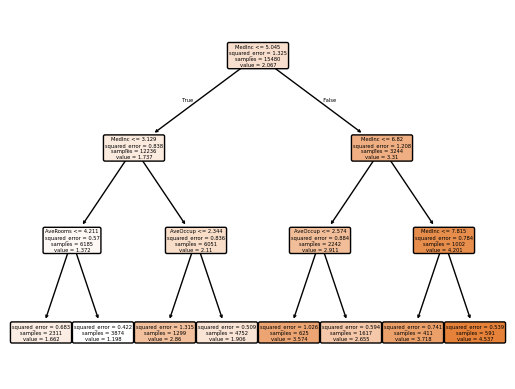

In [39]:
dt_our_best = DecisionTreeRegressor(max_depth=3, random_state=13)
dt_our_best.fit(X_train, y_train)
print(mean_squared_error(y_test, dt_our_best.predict(X_test)))

plot_tree(dt_our_best, feature_names=X.columns, filled=True, rounded=True)
plt.show()

In [40]:
dt_gs_best = DecisionTreeRegressor(max_depth=14,  min_samples_leaf=13, random_state=13)
dt_gs_best.fit(X_train, y_train)
mean_squared_error(y_test, dt_gs_best.predict(X_test))

0.37514221932994596

**Важность признаков**

In [41]:
df_importances = pd.DataFrame({
    "feature": X.columns,
    "importance": dt.feature_importances_
}).sort_values(by="importance", ascending=False).reset_index(drop=True)

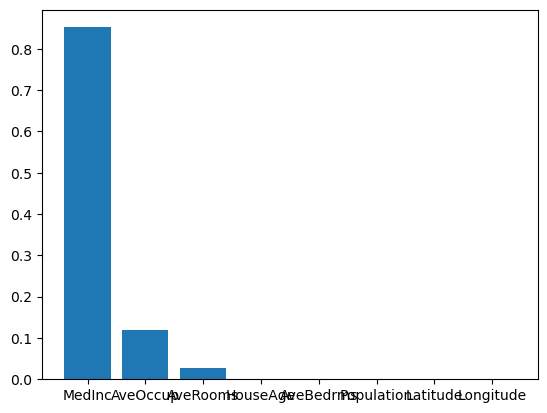

In [42]:
plt.bar(df_importances['feature'], df_importances['importance'])
plt.show()

## Решающее дерево из sklearn с учетом стандартизации

In [43]:
housing = fetch_california_housing()

In [44]:
X = pd.DataFrame(data=housing["data"], columns=housing["feature_names"])
y = housing["target"]

In [45]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=13)

In [46]:
from sklearn.preprocessing import StandardScaler

In [47]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.fit_transform(X_test)

In [48]:
X_train_scaled

array([[-0.18148348,  0.57913684, -0.34002073, ..., -0.08711252,
        -0.67176218,  0.67560682],
       [-0.46832739,  0.57913684, -0.43630412, ...,  0.01224776,
        -0.68572832,  0.60599389],
       [-1.14166794, -1.4097349 ,  6.17916058, ..., -0.12563388,
         2.11215576, -0.74151362],
       ...,
       [-0.72630784, -0.69374107,  0.33043315, ..., -0.07749868,
         1.00417504, -1.34316826],
       [ 1.17304553, -1.88706411,  0.01710877, ...,  0.04043715,
        -1.27696173,  1.20764853],
       [-0.85076839,  1.37468553,  0.19964864, ...,  0.05642674,
         0.97158737, -1.28847239]], shape=(15480, 8))

In [49]:
X_train_scaled.shape

(15480, 8)

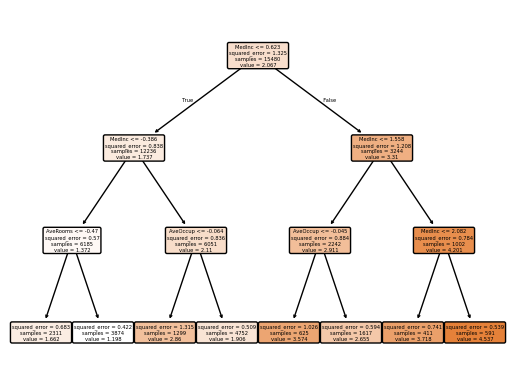

In [50]:
dt = DecisionTreeRegressor(max_depth=3, random_state=13)
dt.fit(X_train_scaled, y_train)

plot_tree(dt, feature_names=X.columns, filled=True, rounded=True)
plt.show()

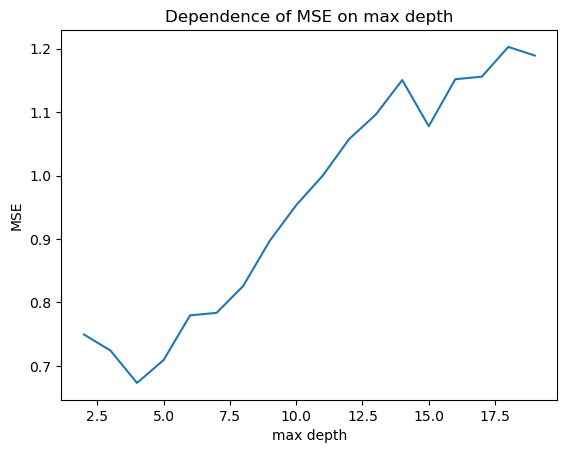

In [51]:
max_depth_array = range(2, 20)
mse_array = []

for max_depth in max_depth_array:
    dt = DecisionTreeRegressor(max_depth=max_depth, random_state=13)
    dt.fit(X_train_scaled, y_train)
    mse_array.append(mean_squared_error(y_test, dt.predict(X_test_scaled)))

plt.plot(max_depth_array, mse_array)
plt.title("Dependence of MSE on max depth")
plt.xlabel("max depth")
plt.ylabel("MSE")
plt.show()

In [52]:
pd.DataFrame({
    "max_depth": max_depth_array,
    "MSE": mse_array
}).sort_values(by="MSE").reset_index(drop=True)

,max_depth,MSE
0,4,0.673120
1,5,0.709018
2,3,0.724130
3,2,0.749546
4,6,0.779608
5,7,0.783609
6,8,0.825763
7,9,0.896904
8,10,0.953257
9,11,0.999877


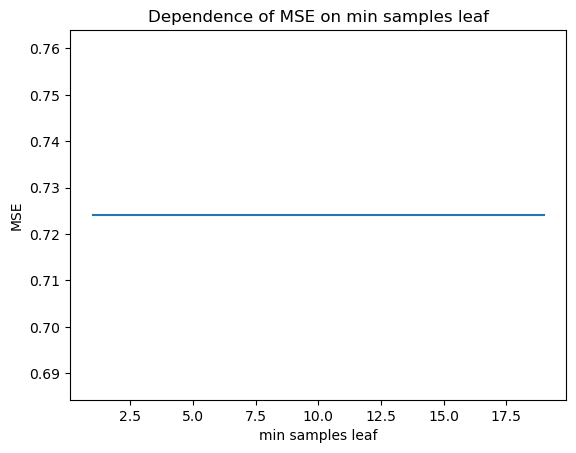

In [53]:
min_samples_leaf_array = range(1, 20)
mse_array = []

for min_samples_leaf in min_samples_leaf_array:
    dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=min_samples_leaf, random_state=13)
    dt.fit(X_train_scaled, y_train)
    mse_array.append(mean_squared_error(y_test, dt.predict(X_test_scaled)))

plt.plot(min_samples_leaf_array, mse_array)
plt.title("Dependence of MSE on min samples leaf")
plt.xlabel("min samples leaf")
plt.ylabel("MSE")
plt.show()

In [54]:
pd.DataFrame({
    "min_samples_leaf": min_samples_leaf_array,
    "MSE": mse_array
}).sort_values(by="MSE").reset_index(drop=True)

,min_samples_leaf,MSE
0,1,0.72413
1,2,0.72413
2,3,0.72413
3,4,0.72413
4,5,0.72413
5,6,0.72413
6,7,0.72413
7,8,0.72413
8,9,0.72413
9,10,0.72413


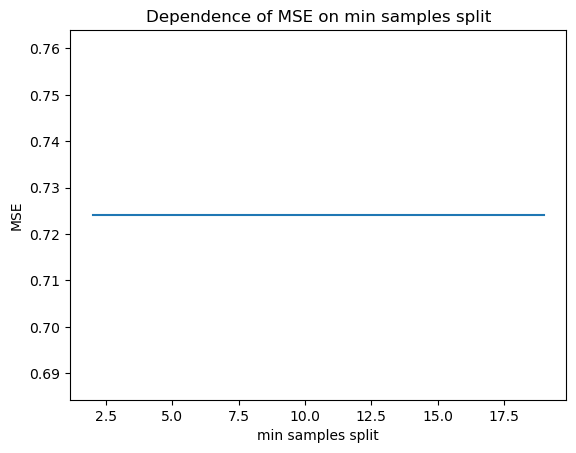

In [55]:
min_samples_split_array = range(2, 20)
mse_array = []

for min_samples_split in min_samples_split_array:
    dt = DecisionTreeRegressor(max_depth=3, min_samples_leaf=11, min_samples_split=min_samples_split, random_state=13)
    dt.fit(X_train_scaled, y_train)
    mse_array.append(mean_squared_error(y_test, dt.predict(X_test_scaled)))

plt.plot(min_samples_split_array, mse_array)
plt.title("Dependence of MSE on min samples split")
plt.xlabel("min samples split")
plt.ylabel("MSE")
plt.show()

In [56]:
pd.DataFrame({
    "min_samples_split": min_samples_split_array,
    "MSE": mse_array
}).sort_values(by="MSE").reset_index(drop=True)

,min_samples_split,MSE
0,2,0.72413
1,3,0.72413
2,4,0.72413
3,5,0.72413
4,6,0.72413
5,7,0.72413
6,8,0.72413
7,9,0.72413
8,10,0.72413
9,11,0.72413


In [36]:
%%time
from sklearn.model_selection import GridSearchCV
gs = GridSearchCV(DecisionTreeRegressor(random_state=13),
                  param_grid={
                      'max_features': ['auto', 'log2', 'sqrt'],
                      'max_depth': list(range(2, 20)) + [None],
                      'min_samples_leaf': list(range(1, 20)) + [None]
                  },
                  cv=5,
                  scoring='neg_mean_squared_error')
gs.fit(X_train_scaled, y_train)

CPU times: user 2min 1s, sys: 306 ms, total: 2min 1s
Wall time: 2min 2s


/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py:516: FitFailedWarning: 
2090 fits failed out of a total of 5700.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
1900 fits failed with the following error:
Traceback (most recent call last):
  File "/opt/conda/lib/python3.13/site-packages/sklearn/model_selection/_validation.py", line 859, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 1358, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/opt/conda/lib/python3.13/site-packages/sklearn/base.py", line 471, in _validate_params
    valida

,estimator,DecisionTreeR...ndom_state=13)
,param_grid,"{'max_depth': [2, 3, ...], 'max_features': ['auto', 'log2', ...], 'min_samples_leaf': [1, 2, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,None
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'squared_error'


In [37]:
gs.best_params_

{'max_depth': 14, 'max_features': 'log2', 'min_samples_leaf': 13}

0.7241303100888076


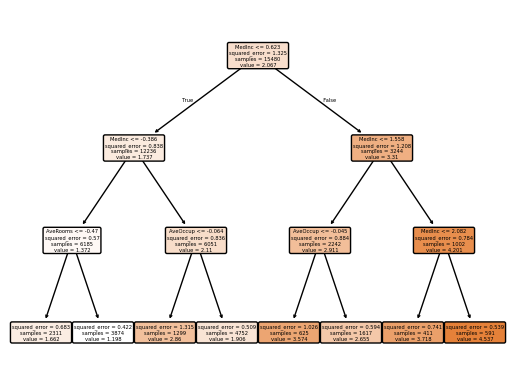

In [57]:
dt_our_best = DecisionTreeRegressor(max_depth=3, random_state=13)
dt_our_best.fit(X_train_scaled, y_train)
print(mean_squared_error(y_test, dt_our_best.predict(X_test_scaled)))

plot_tree(dt_our_best, feature_names=X.columns, filled=True, rounded=True)
plt.show()

In [58]:
dt_gs_best = DecisionTreeRegressor(max_depth=14,  min_samples_leaf=13, random_state=13)
dt_gs_best.fit(X_train_scaled, y_train)
mean_squared_error(y_test, dt_gs_best.predict(X_test_scaled))

0.8256112927249627

In [59]:
df_importances = pd.DataFrame({
    "feature": X.columns,
    "importance": dt.feature_importances_
}).sort_values(by="importance", ascending=False).reset_index(drop=True)

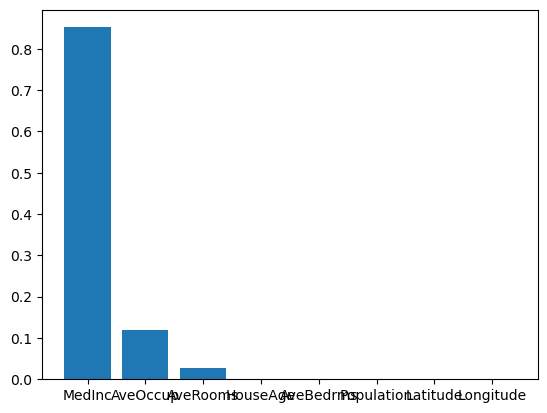

In [60]:
plt.bar(df_importances['feature'], df_importances['importance'])
plt.show()

При включении в анализ стандартизации, мы получили результаты хуже, так как значения средеквадратической ошибки увеличились. Анализ проводился с глубиной дерева max_depth = 3. Можно также отметить, что при включении стандартизации дерево решений с max_depth выбранной нами (3), показало лучшие результаты, чем дерево, max_depth которого было выбрано с помощью GridSearchCV, а без учета стандартизации наоборот.